In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import docx
import docx2txt
import pdfplumber



In [2]:
# Importing the Files
file_path = r"C:\Users\USER\Downloads\RCs_P629\Resumes"


In [3]:
# 
records = []

for folder in os.listdir(file_path):
    folder_path = os.path.join(file_path, folder)

    if not os.path.isdir(folder_path):
        continue

    for file in os.listdir(folder_path):
        full_path = os.path.join(folder_path, file)
        file_lower = file.lower()

        if file_lower.endswith(".docx"):
            file_type = "DOCX"
        elif file_lower.endswith(".doc"):
            file_type = "DOC"
        elif file_lower.endswith(".pdf"):
            file_type = "PDF"
        else:
            continue  

        records.append({
            "Profile": folder,
            "Resume": full_path,
            "File_Type": file_type
        })


In [4]:
# Creating Dataframe
resume_df = pd.DataFrame(records)
resume_df.head()

,Profile,Resume,File_Type
0,Peoplesoft resumes,C:\Users\USER\Downloads\RCs_P629\Resumes\Peopl...,DOCX
1,Peoplesoft resumes,C:\Users\USER\Downloads\RCs_P629\Resumes\Peopl...,DOC
2,Peoplesoft resumes,C:\Users\USER\Downloads\RCs_P629\Resumes\Peopl...,DOC
3,Peoplesoft resumes,C:\Users\USER\Downloads\RCs_P629\Resumes\Peopl...,DOCX
4,Peoplesoft resumes,C:\Users\USER\Downloads\RCs_P629\Resumes\Peopl...,DOC


In [5]:
print("DOC files :", (resume_df['File_Type'] == 'DOC').sum())
print("DOCX files:", (resume_df['File_Type'] == 'DOCX').sum())
print("PDF files :", (resume_df['File_Type'] == 'PDF').sum())


DOC files : 26
DOCX files: 52
PDF files : 1


In [6]:
resume_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79 entries, 0 to 78
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Profile    79 non-null     object
 1   Resume     79 non-null     object
 2   File_Type  79 non-null     object
dtypes: object(3)
memory usage: 2.0+ KB


In [7]:
resume_df.shape

(79, 3)

In [8]:
 # missing values
resume_df.isnull().sum() 


Profile      0
Resume       0
File_Type    0
dtype: int64

In [9]:
# duplicates
resume_df.duplicated().sum()  

0

In [10]:
# value count
resume_df['File_Type'].value_counts()


File_Type
DOCX    52
DOC     26
PDF      1
Name: count, dtype: int64

In [11]:
resume_df[resume_df['Profile'] == ""]


,Profile,Resume,File_Type


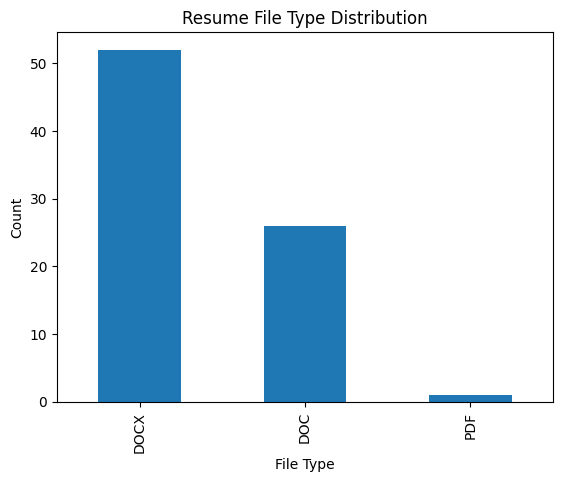

In [12]:
# 
resume_df['File_Type'].value_counts().plot(kind='bar')
plt.title("Resume File Type Distribution")
plt.xlabel("File Type")
plt.ylabel("Count")
plt.show()


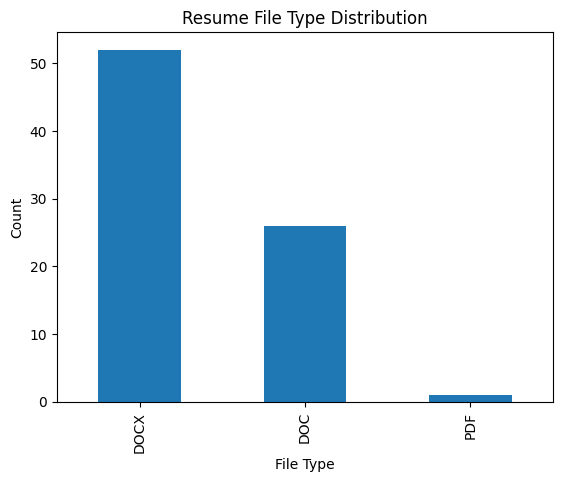

In [13]:
# Visualization of files
resume_df['File_Type'].value_counts().plot(kind='bar')
plt.title("Resume File Type Distribution")
plt.xlabel("File Type")
plt.ylabel("Count")
plt.show()


In [14]:
profile_counts = resume_df.Profile.value_counts()
profile_counts

Profile
React Developer                    24
workday resumes                    21
Peoplesoft resumes                 20
SQL Developer Lightning insight    14
Name: count, dtype: int64

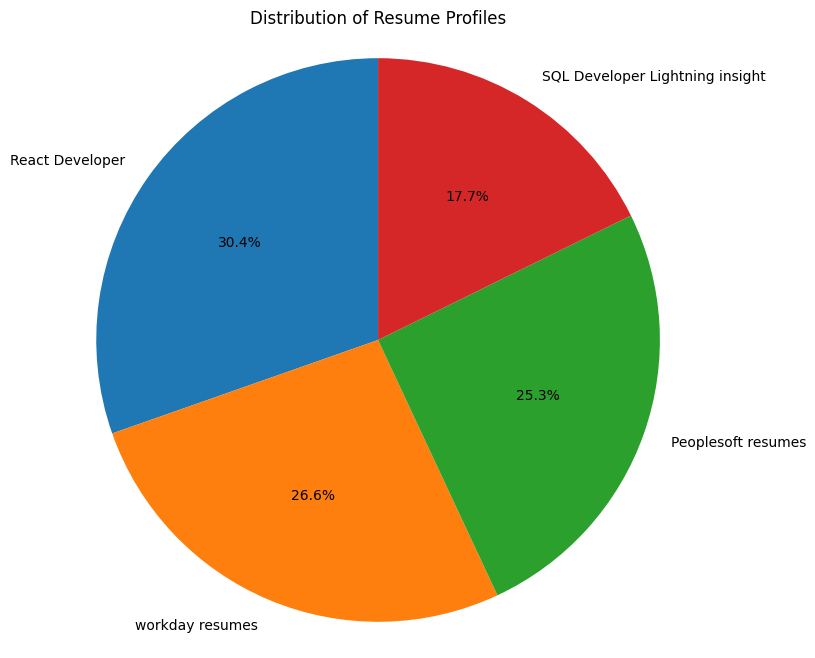

In [15]:
plt.figure(figsize=(8,8))
plt.pie(
    profile_counts.values,
    labels=profile_counts.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title("Distribution of Resume Profiles")
plt.axis('equal')
plt.show()


In [16]:
# Data Cleaning 

In [17]:
resume_df.sample(3)

,Profile,Resume,File_Type
67,workday resumes,C:\Users\USER\Downloads\RCs_P629\Resumes\workd...,DOCX
78,workday resumes,C:\Users\USER\Downloads\RCs_P629\Resumes\workd...,DOCX
31,React Developer,C:\Users\USER\Downloads\RCs_P629\Resumes\React...,DOCX


In [18]:
#  Functions to extract text
def extract_pdf(path):
    text = ""
    with pdfplumber.open(path) as pdf:
        for page in pdf.pages:
            t = page.extract_text()
            if t and t.strip() != '':
                text += t + "\n"
    return text

def extract_docx(path):
    document = docx.Document(path)
    full_text = [para.text for para in document.paragraphs if para.text.strip() != '']
    return "\n".join(full_text)

def extract_doc(path):
    try:
        result = subprocess.run(["antiword", path], capture_output=True, text=True)
        return result.stdout
    except Exception as e:
        return f"[ERROR extracting {path}: {e}]"

# --- Extract text for all resumes ---
extracted_texts = []

for index, row in tqdm(resume_df.iterrows(), total=len(resume_df)):
    resume_file = row['Resume']
    text = ""

    try:
        if resume_file.lower().endswith(".pdf"):
            text = extract_pdf(resume_file)
        elif resume_file.lower().endswith(".docx"):
            text = extract_docx(resume_file)
        elif resume_file.lower().endswith(".doc"):
            text = extract_doc(resume_file)
        else:
            text = "[Unsupported file type]"

    except Exception as e:
        text = f"[Error extracting {resume_file}: {e}]"

    # If extraction returned empty, replace with blank string
    if not text:
        text = ""

    extracted_texts.append(text)

resume_df["Text"] = extracted_texts

print ("ALL resumes extracted successfully!")


100%|██████████████████████████████████████████████████████████████████████████████████| 79/79 [00:04<00:00, 16.20it/s]

ALL resumes extracted successfully!


In [19]:
resume_df.head()

,Profile,Resume,File_Type,Text
0,Peoplesoft resumes,C:\Users\USER\Downloads\RCs_P629\Resumes\Peopl...,DOCX,Anubhav Kumar Singh\t\t\n To work in a glob...
1,Peoplesoft resumes,C:\Users\USER\Downloads\RCs_P629\Resumes\Peopl...,DOC,[ERROR extracting C:\Users\USER\Downloads\RCs_...
2,Peoplesoft resumes,C:\Users\USER\Downloads\RCs_P629\Resumes\Peopl...,DOC,[ERROR extracting C:\Users\USER\Downloads\RCs_...
3,Peoplesoft resumes,C:\Users\USER\Downloads\RCs_P629\Resumes\Peopl...,DOCX,Murali\nExperience Summary \nI have 6 years of...
4,Peoplesoft resumes,C:\Users\USER\Downloads\RCs_P629\Resumes\Peopl...,DOC,[ERROR extracting C:\Users\USER\Downloads\RCs_...


In [20]:
resume_df.columns

Index(['Profile', 'Resume', 'File_Type', 'Text'], dtype='object')

In [21]:
resume_df['extraction_status'] = resume_df['Text'].apply(
    lambda x: 'failed' if x is None or str(x).startswith('[ERROR extracting') else 'success'
)


In [22]:
resume_df['extraction_status'].value_counts()


extraction_status
success    53
failed     26
Name: count, dtype: int64

In [23]:
# Keep only successfully extracted resumes
clean_df = resume_df[resume_df['extraction_status'] == 'success'].copy()

# Keep only necessary columns for text cleaning / FE
clean_df = clean_df[['Profile', 'Text']]

clean_df.head()


,Profile,Text
0,Peoplesoft resumes,Anubhav Kumar Singh\t\t\n To work in a glob...
3,Peoplesoft resumes,Murali\nExperience Summary \nI have 6 years of...
5,Peoplesoft resumes,PROFILE SUMMARY\nI have overall 6.8 years’ exp...
7,Peoplesoft resumes,PeopleSoft Admin\nVARKALA VIKAS\nCareer Objec...
10,Peoplesoft resumes,PeopleSoft Administration\nVivekanand Sayana ...


In [24]:
clean_df['Profile'].count()

53

In [25]:
clean_df['clean_text'] = clean_df['Text']
clean_df.head(3)

,Profile,Text,clean_text
0,Peoplesoft resumes,Anubhav Kumar Singh\t\t\n To work in a glob...,Anubhav Kumar Singh\t\t\n To work in a glob...
3,Peoplesoft resumes,Murali\nExperience Summary \nI have 6 years of...,Murali\nExperience Summary \nI have 6 years of...
5,Peoplesoft resumes,PROFILE SUMMARY\nI have overall 6.8 years’ exp...,PROFILE SUMMARY\nI have overall 6.8 years’ exp...


In [26]:
from unidecode import unidecode
import re

def clean_resume(text):
    text = str(text)                       # ensure string
    text = unidecode(text)                 # remove accents / special unicode
    text = text.lower()                     # lowercase
    text = re.sub(r'\n', ' ', text)        # remove newlines
    text = re.sub(r'\t', ' ', text)        # remove tabs
    text = re.sub(r'[^a-z\s]', ' ', text)  # remove everything except letters a-z and spaces
    text = re.sub(r'\s+', ' ', text).strip() # normalize spaces
    return text

# Apply to your DataFrame
clean_df['clean_text'] = clean_df['Text'].apply(clean_resume)


In [27]:
# Text length (characters)
clean_df['text_length'] = clean_df['clean_text'].apply(lambda x: len(str(x)))

# Word count (words)
clean_df['word_count'] = clean_df['clean_text'].apply(lambda x: len(str(x).split()))


In [28]:
clean_df.head(5)

,Profile,Text,clean_text,text_length,word_count
0,Peoplesoft resumes,Anubhav Kumar Singh\t\t\n To work in a glob...,anubhav kumar singh to work in a globally comp...,6565,901
3,Peoplesoft resumes,Murali\nExperience Summary \nI have 6 years of...,murali experience summary i have years of expe...,3682,512
5,Peoplesoft resumes,PROFILE SUMMARY\nI have overall 6.8 years’ exp...,profile summary i have overall years experienc...,3189,446
7,Peoplesoft resumes,PeopleSoft Admin\nVARKALA VIKAS\nCareer Objec...,peoplesoft admin varkala vikas career objectiv...,6948,949
10,Peoplesoft resumes,PeopleSoft Administration\nVivekanand Sayana ...,peoplesoft administration vivekanand sayana ca...,13868,1962


In [29]:
# Tokenization & NLP processing

In [30]:
import nltk
nltk.download('punkt')
nltk.download('wordnet')
nltk.download('stopwords')

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def nlp_preprocess(text):
    # Tokenize
    tokens = word_tokenize(text)
    # Lowercase
    tokens = [t.lower() for t in tokens]
    # Remove stopwords
    tokens = [t for t in tokens if t not in stop_words]
    # Remove punctuation / numbers
    tokens = [t for t in tokens if t.isalpha()]
    # Lemmatize
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return tokens

clean_df['tokens'] = clean_df['clean_text'].apply(nlp_preprocess)


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [31]:
clean_df['clean_text'] = clean_df['tokens'].apply(lambda x: ' '.join(x))
clean_df.head(5)

,Profile,Text,clean_text,text_length,word_count,tokens
0,Peoplesoft resumes,Anubhav Kumar Singh\t\t\n To work in a glob...,anubhav kumar singh work globally competitive ...,6565,901,"[anubhav, kumar, singh, work, globally, compet..."
3,Peoplesoft resumes,Murali\nExperience Summary \nI have 6 years of...,murali experience summary year experience work...,3682,512,"[murali, experience, summary, year, experience..."
5,Peoplesoft resumes,PROFILE SUMMARY\nI have overall 6.8 years’ exp...,profile summary overall year experience people...,3189,446,"[profile, summary, overall, year, experience, ..."
7,Peoplesoft resumes,PeopleSoft Admin\nVARKALA VIKAS\nCareer Objec...,peoplesoft admin varkala vikas career objectiv...,6948,949,"[peoplesoft, admin, varkala, vikas, career, ob..."
10,Peoplesoft resumes,PeopleSoft Administration\nVivekanand Sayana ...,peoplesoft administration vivekanand sayana ca...,13868,1962,"[peoplesoft, administration, vivekanand, sayan..."


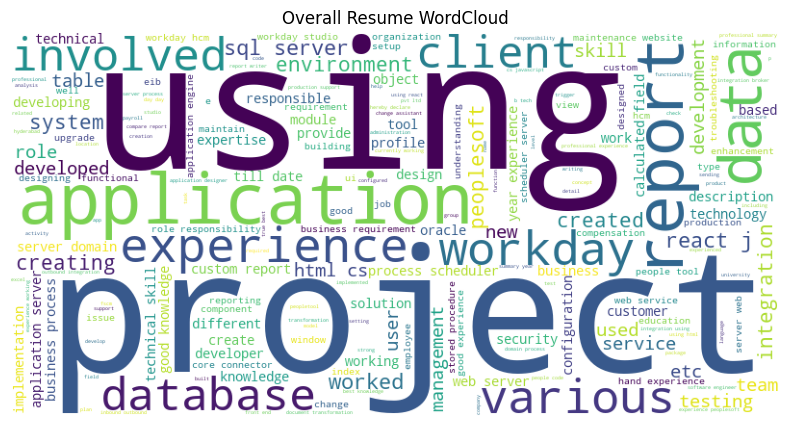

In [32]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

text = " ".join(clean_df['clean_text'])

wc = WordCloud(
    width=800,
    height=400,
    background_color='white'
).generate(text)

plt.figure(figsize=(10,5))
plt.imshow(wc)
plt.axis('off')
plt.title("Overall Resume WordCloud")
plt.show()


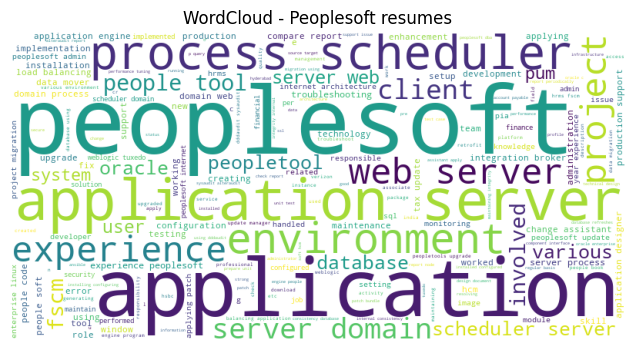

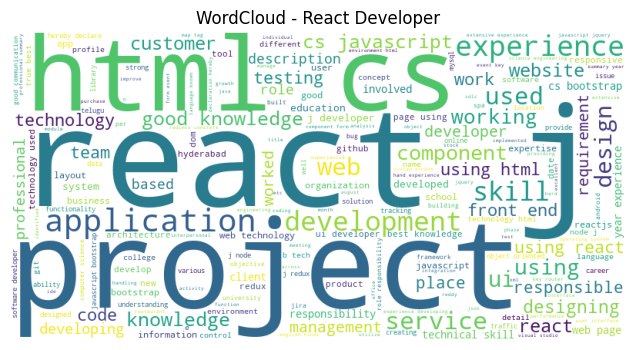

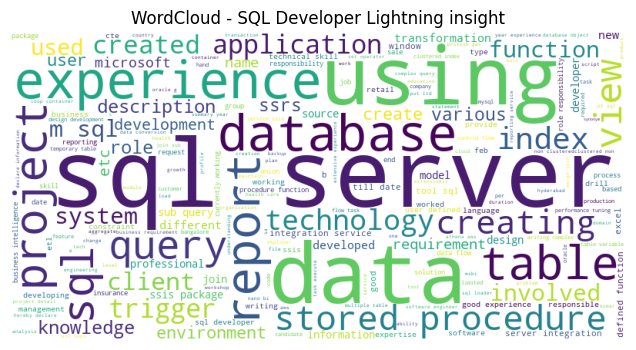

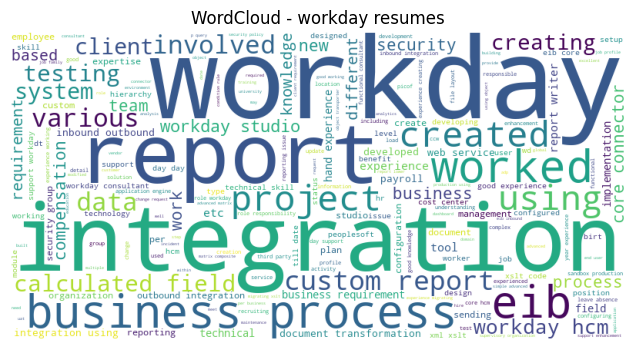

In [33]:
for profile in clean_df['Profile'].unique():
    text = " ".join(clean_df[clean_df['Profile'] == profile]['clean_text'])
    wc = WordCloud(
        width=800,
        height=400,
        background_color='white'
    ).generate(text)

    plt.figure(figsize=(8,4))
    plt.imshow(wc)
    plt.axis('off')
    plt.title(f"WordCloud - {profile}")
    plt.show()


In [34]:
# Feature Engineering

In [35]:
# Train Test Split

In [36]:
from sklearn.model_selection import train_test_split

X = clean_df['clean_text']
y = clean_df['Profile']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)


In [37]:
# TF IDF vectorizer 
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1,2),
    max_features=5000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)


In [38]:
# MODEL BUILDING

In [39]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, f1_score


lr = LogisticRegression(
    max_iter=1000,
    n_jobs=-1
)

lr.fit(X_train_tfidf, y_train)


# Predictions
y_train_pred = lr.predict(X_train_tfidf)
y_test_pred  = lr.predict(X_test_tfidf)

# Accuracy & # Classification report
print("Accuracy of training set :", accuracy_score(y_train, y_train_pred))
print("Accuracy of test set    :", accuracy_score(y_test, y_test_pred))

print("\nClassification report for Logistic Regression:")
print(classification_report(y_test, y_test_pred))

print("F1 Macro:", f1_score(y_test, y_test_pred, average='macro'))


Accuracy of training set : 1.0
Accuracy of test set    : 0.8181818181818182

Classification report for Logistic Regression:
                                 precision    recall  f1-score   support

             Peoplesoft resumes       1.00      0.50      0.67         2
                React Developer       0.71      1.00      0.83         5
SQL Developer Lightning insight       1.00      0.50      0.67         2
                workday resumes       1.00      1.00      1.00         2

                       accuracy                           0.82        11
                      macro avg       0.93      0.75      0.79        11
                   weighted avg       0.87      0.82      0.80        11

F1 Macro: 0.7916666666666666


In [40]:
# Decision Tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train_tfidf, y_train)

# Prediction
y_train_pred = dt.predict(X_train_tfidf)
y_test_pred  = dt.predict(X_test_tfidf)

# Accuracy & # Classification report
print("Accuracy of training set :", accuracy_score(y_train, y_train_pred))
print("Accuracy of test set    :", accuracy_score(y_test, y_test_pred))
print("\nClassification report for Decision Tree:")
print(classification_report(y_test, y_test_pred))
print("F1 Macro:", f1_score(y_test, y_test_pred, average='macro'))


Accuracy of training set : 1.0
Accuracy of test set    : 0.9090909090909091

Classification report for Decision Tree:
                                 precision    recall  f1-score   support

             Peoplesoft resumes       0.67      1.00      0.80         2
                React Developer       1.00      0.80      0.89         5
SQL Developer Lightning insight       1.00      1.00      1.00         2
                workday resumes       1.00      1.00      1.00         2

                       accuracy                           0.91        11
                      macro avg       0.92      0.95      0.92        11
                   weighted avg       0.94      0.91      0.91        11

F1 Macro: 0.9222222222222223


In [41]:
# KNN
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_tfidf, y_train)

# Prediction
y_train_pred = knn.predict(X_train_tfidf)
y_test_pred  = knn.predict(X_test_tfidf)

# Accuracy & # Classification report
print("Accuracy of training set :", accuracy_score(y_train, y_train_pred))
print("Accuracy of test set    :", accuracy_score(y_test, y_test_pred))
print("\nClassification report for KNN:")
print(classification_report(y_test, y_test_pred))
print("F1 Macro:", f1_score(y_test, y_test_pred, average='macro'))


Accuracy of training set : 0.9761904761904762
Accuracy of test set    : 1.0

Classification report for KNN:
                                 precision    recall  f1-score   support

             Peoplesoft resumes       1.00      1.00      1.00         2
                React Developer       1.00      1.00      1.00         5
SQL Developer Lightning insight       1.00      1.00      1.00         2
                workday resumes       1.00      1.00      1.00         2

                       accuracy                           1.00        11
                      macro avg       1.00      1.00      1.00        11
                   weighted avg       1.00      1.00      1.00        11

F1 Macro: 1.0


In [42]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_tfidf, y_train)

# Prediction
y_train_pred = rf.predict(X_train_tfidf)
y_test_pred  = rf.predict(X_test_tfidf)

# Accuracy & # Classification report, F1
print("Accuracy of training set :", accuracy_score(y_train, y_train_pred))
print("Accuracy of test set    :", accuracy_score(y_test, y_test_pred))
print("\nClassification report for Random Forest:")
print(classification_report(y_test, y_test_pred))
print("F1 Macro:", f1_score(y_test, y_test_pred, average='macro'))


Accuracy of training set : 1.0
Accuracy of test set    : 1.0

Classification report for Random Forest:
                                 precision    recall  f1-score   support

             Peoplesoft resumes       1.00      1.00      1.00         2
                React Developer       1.00      1.00      1.00         5
SQL Developer Lightning insight       1.00      1.00      1.00         2
                workday resumes       1.00      1.00      1.00         2

                       accuracy                           1.00        11
                      macro avg       1.00      1.00      1.00        11
                   weighted avg       1.00      1.00      1.00        11

F1 Macro: 1.0


In [43]:
# Gradient Boosting
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(n_estimators=100, random_state=42)
gb.fit(X_train_tfidf, y_train)

# Prediction
y_train_pred = gb.predict(X_train_tfidf)
y_test_pred  = gb.predict(X_test_tfidf)

# Accuracy & # Classification report, F1
print("Accuracy of training set :", accuracy_score(y_train, y_train_pred))
print("Accuracy of test set    :", accuracy_score(y_test, y_test_pred))
print("\nClassification report for Gradient Boosting:")
print(classification_report(y_test, y_test_pred))
print("F1 Macro:", f1_score(y_test, y_test_pred, average='macro'))


Accuracy of training set : 1.0
Accuracy of test set    : 1.0

Classification report for Gradient Boosting:
                                 precision    recall  f1-score   support

             Peoplesoft resumes       1.00      1.00      1.00         2
                React Developer       1.00      1.00      1.00         5
SQL Developer Lightning insight       1.00      1.00      1.00         2
                workday resumes       1.00      1.00      1.00         2

                       accuracy                           1.00        11
                      macro avg       1.00      1.00      1.00        11
                   weighted avg       1.00      1.00      1.00        11

F1 Macro: 1.0


In [44]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(), 
    n_estimators=50,
    random_state=42
)

bag.fit(X_train_tfidf, y_train)

# Prediction
y_train_pred = bag.predict(X_train_tfidf)
y_test_pred  = bag.predict(X_test_tfidf)

# Accuracy & # Classification report, F1
print("Accuracy of training set :", accuracy_score(y_train, y_train_pred))
print("Accuracy of test set    :", accuracy_score(y_test, y_test_pred))
print("\nClassification report for Bagging Classifier:")
print(classification_report(y_test, y_test_pred))
print("F1 Macro:", f1_score(y_test, y_test_pred, average='macro'))


Accuracy of training set : 1.0
Accuracy of test set    : 1.0

Classification report for Bagging Classifier:
                                 precision    recall  f1-score   support

             Peoplesoft resumes       1.00      1.00      1.00         2
                React Developer       1.00      1.00      1.00         5
SQL Developer Lightning insight       1.00      1.00      1.00         2
                workday resumes       1.00      1.00      1.00         2

                       accuracy                           1.00        11
                      macro avg       1.00      1.00      1.00        11
                   weighted avg       1.00      1.00      1.00        11

F1 Macro: 1.0


In [45]:
# Linear SVM
from sklearn.svm import LinearSVC

svm = LinearSVC(max_iter=1000)
svm.fit(X_train_tfidf, y_train)

# Prediction 
y_train_pred = svm.predict(X_train_tfidf)
y_test_pred  = svm.predict(X_test_tfidf)

# Accuracy & # Classification report, F1
print("Accuracy of training set :", accuracy_score(y_train, y_train_pred))
print("Accuracy of test set    :", accuracy_score(y_test, y_test_pred))
print("\nClassification report for Linear SVM:")
print(classification_report(y_test, y_test_pred))
print("F1 Macro:", f1_score(y_test, y_test_pred, average='macro'))


Accuracy of training set : 1.0
Accuracy of test set    : 1.0

Classification report for Linear SVM:
                                 precision    recall  f1-score   support

             Peoplesoft resumes       1.00      1.00      1.00         2
                React Developer       1.00      1.00      1.00         5
SQL Developer Lightning insight       1.00      1.00      1.00         2
                workday resumes       1.00      1.00      1.00         2

                       accuracy                           1.00        11
                      macro avg       1.00      1.00      1.00        11
                   weighted avg       1.00      1.00      1.00        11

F1 Macro: 1.0


In [ ]:
#Tuning

In [119]:
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, f1_score


In [121]:
# Parameters
param_grid = {
    'C': [0.1, 1, 10]
}


In [123]:
# Grid SearchCV
grid = GridSearchCV(
    LinearSVC(max_iter=2000),
    param_grid,
    scoring='f1_macro',
    cv=5
)


In [125]:
grid.fit(X_train_tfidf, y_train)


,estimator,LinearSVC(max_iter=2000)
,param_grid,"{'C': [0.1, 1, ...]}"
,scoring,'f1_macro'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [127]:
best_svm = grid.best_estimator_


In [129]:
y_test_pred = best_svm.predict(X_test_tfidf)

print(classification_report(y_test, y_test_pred))
print("F1 Macro:", f1_score(y_test, y_test_pred, average='macro'))


                                 precision    recall  f1-score   support

             Peoplesoft resumes       1.00      1.00      1.00         2
                React Developer       1.00      1.00      1.00         5
SQL Developer Lightning insight       1.00      1.00      1.00         2
                workday resumes       1.00      1.00      1.00         2

                       accuracy                           1.00        11
                      macro avg       1.00      1.00      1.00        11
                   weighted avg       1.00      1.00      1.00        11

F1 Macro: 1.0
